# Image Processing Basics for Iris Recognition

This notebook explores fundamental image processing operations that will later
be used in the iris segmentation and preprocessing pipeline.

## Topics

- Images as numerical arrays
- Grayscale images
- Pixel intensity
- Histograms
- Gaussian smoothing
- Thresholding
- Edge detection

## 1. Setup

We begin by importing the libraries used throughout this notebook:

- **NumPy** for numerical arrays and matrix operations
- **OpenCV** for image processing operations
- **Matplotlib** for visualization

These tools will later be used to build the preprocessing and segmentation stages
of the iris verification pipeline.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 2. Images as Numerical Arrays

A grayscale image can be represented as a two-dimensional matrix.

Each element of the matrix corresponds to a **pixel intensity**.

For an 8-bit grayscale image:

- `0` represents black
- `255` represents white
- values between them represent different shades of gray

The small 3 × 3 image below allows us to study image-processing operations
before applying them to real iris images.

In [2]:
image = np.array([
    [0,   50,  100],
    [150, 200, 250],
    [30,  120, 220]
], dtype=np.uint8)

print(image)

[[  0  50 100]
 [150 200 250]
 [ 30 120 220]]


### Inspecting the Image

Before processing an image, it is useful to inspect its basic properties.

- `shape` describes the dimensions of the image
- `dtype` describes how pixel values are stored
- `min()` returns the minimum intensity
- `max()` returns the maximum intensity

The image uses `uint8`, an unsigned 8-bit integer type capable of representing
values from 0 to 255.

In [3]:
print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum:", image.min())
print("Maximum:", image.max())

Shape: (3, 3)
Data type: uint8
Minimum: 0
Maximum: 250


In [ ]:
### Visualizing the Matrix as an Image

Although the image is stored as a numerical matrix, Matplotlib can visualize
the values as pixel intensities.

The grayscale colormap maps low values to dark pixels and high values to
bright pixels.

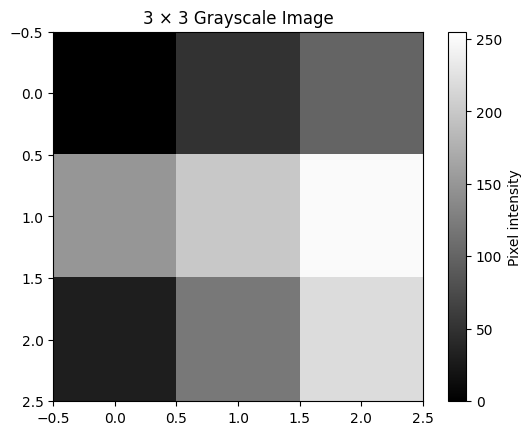

In [4]:
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.colorbar(label="Pixel intensity")
plt.title("3 × 3 Grayscale Image")
plt.show()

### Accessing Individual Pixels

NumPy allows individual pixels to be accessed using:

`image[row, column]`

Python uses zero-based indexing, meaning that index `0` refers to the first
row or column.

Understanding pixel coordinates will become important when working with
iris boundaries and image regions.

In [ ]:
image[1, 2]

np.uint8(250)

## 3. Thresholding and Binary Masks

Thresholding separates pixels according to their intensity.

For a threshold \(T\), we can test:

\[
I(x,y) < T
\]

where \(I(x,y)\) represents the intensity of the pixel at position \((x,y)\).

Pixels satisfying the condition are marked as `True`, producing a
**boolean mask**.

In iris images, a similar idea can help identify dark regions that may
contain the pupil.

In [12]:
dark_pixels = image < 100

print(dark_pixels)

[[ True  True False]
 [False False False]
 [ True False False]]


### Creating a Binary Image

A boolean mask can be converted into a binary image containing only two values.

Here:

- pixels below the threshold become `255`
- all other pixels become `0`

The white pixels therefore represent the regions selected by our condition.

Importantly, a dark pixel is not necessarily part of the pupil. Eyelashes,
shadows, and other dark regions may also satisfy the threshold.

In [13]:
binary_image = np.where(image < 100, 255, 0).astype(np.uint8)

print(binary_image)

[[255 255   0]
 [  0   0   0]
 [255   0   0]]


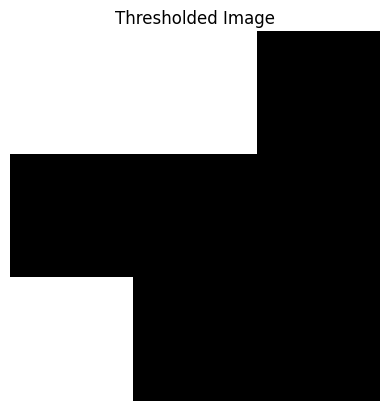

In [16]:
plt.imshow(binary_image, cmap="gray", vmin=0, vmax=255)
plt.title("Thresholded Image")
plt.axis("off")
plt.show()

### Effect of the Threshold Value

The threshold controls how many pixels satisfy the intensity condition.

When using:

\[
I(x,y) < T
\]

increasing \(T\) allows more intensity values to satisfy the condition.

Comparing different thresholds helps demonstrate why selecting an appropriate
threshold is an important part of image segmentation.

In [17]:
binary_100 = np.where(image < 100, 255, 0).astype(np.uint8)
binary_200 = np.where(image < 200, 255, 0).astype(np.uint8)

print("Threshold = 100")
print(binary_100)

print("\nThreshold = 200")
print(binary_200)

Threshold = 100
[[255 255   0]
 [  0   0   0]
 [255   0   0]]

Threshold = 200
[[255 255 255]
 [255   0   0]
 [255 255   0]]


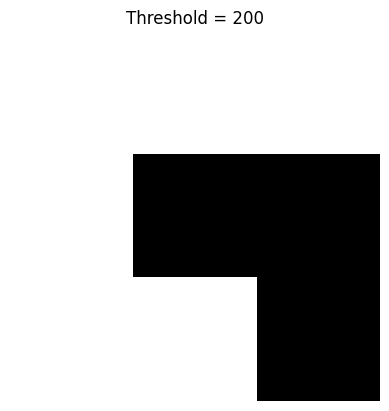

In [18]:
plt.imshow(binary_200, cmap="gray", vmin=0, vmax=255)
plt.title("Threshold = 200")
plt.axis("off")
plt.show()

## 4. Intensity Histograms

An intensity histogram describes the distribution of pixel values in an image.

The horizontal axis represents intensity values, while the vertical axis
represents how many pixels fall within each intensity range.

Histograms do not preserve spatial information. Two different images may have
the same histogram if they contain the same intensity values arranged in
different locations.

Intensity distributions can help us understand image contrast and guide
threshold selection.

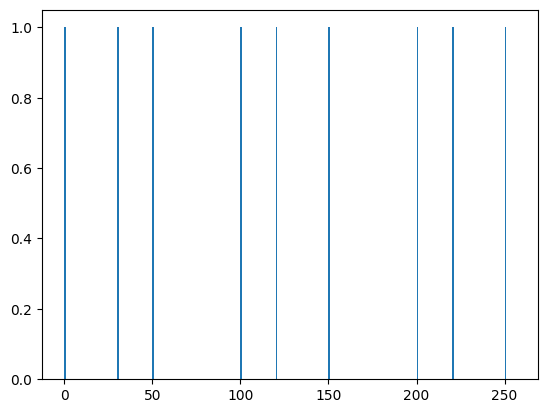

In [20]:
plt.hist(image.ravel(), bins=256, range=(0, 256))
plt.show()

### Effect of the Number of Bins

A histogram groups intensity values into intervals called **bins**.

Using 256 bins provides fine-grained intensity information.

Using only 4 bins divides the 0–255 intensity range into four broader groups:

- 0–63
- 64–127
- 128–191
- 192–255

Reducing the number of bins therefore produces a coarser representation of
the intensity distribution.

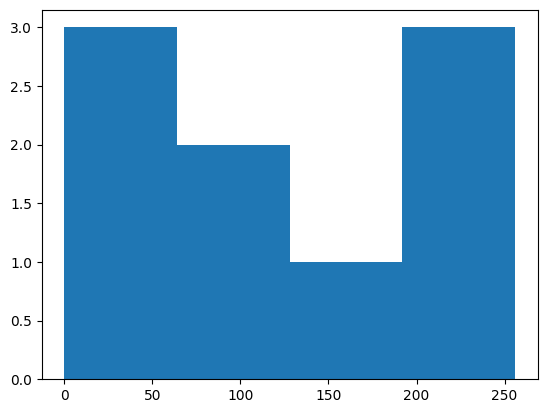

In [21]:
plt.hist(image.ravel(), bins=4, range=(0, 256))
plt.show()

## 5. Spatial Filtering and Kernels

Image processing operations often use the neighborhood surrounding each pixel
rather than considering pixels independently.

A **kernel** is a small matrix that moves across an image and combines
neighboring pixel values.

The following 3 × 3 kernel gives equal weight to all nine pixels:

\[
K =
\frac{1}{9}
\begin{bmatrix}
1 & 1 & 1 \\
1 & 1 & 1 \\
1 & 1 & 1
\end{bmatrix}
\]

This produces a **mean filter**, where each output pixel is based on the
average intensity of its local neighborhood.

In [22]:
kernel = np.ones((3, 3), dtype=np.float32) / 9

print(kernel)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


### Applying the Mean Filter

OpenCV's `filter2D()` applies the kernel across the image.

For each location, neighboring pixel values are combined using the kernel
weights to produce a new pixel value.

This operation smooths local intensity variations and therefore produces
a blurred version of the image.

In [23]:
filtered_image = cv2.filter2D(
    image,
    ddepth=-1,
    kernel=kernel
)

print(filtered_image)

[[133 150 167]
 [102 124 146]
 [152 174 196]]


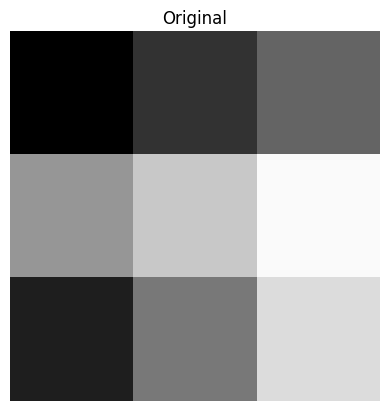

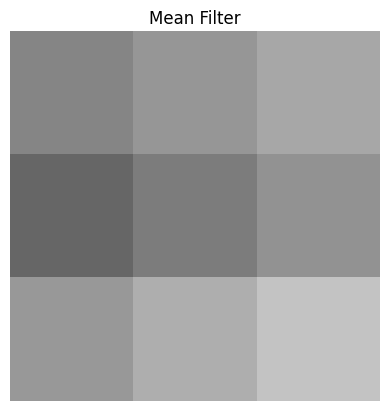

In [24]:
plt.imshow(image, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")
plt.show()

plt.imshow(filtered_image, cmap="gray", vmin=0, vmax=255)
plt.title("Mean Filter")
plt.axis("off")
plt.show()

### Inspecting the Effect of Smoothing

The center pixel originally has an intensity of 200.

With the 3 × 3 mean filter, the center value is replaced by the average
of its neighborhood:

\[
\frac{
0+50+100+
150+200+250+
30+120+220
}{9}
\approx 124.44
\]

The filtered image therefore stores a value close to 124 at the center.

This demonstrates how smoothing reduces strong local intensity differences.

In [25]:
print("Original image:")
print(image)

print("\nFiltered image:")
print(filtered_image)


Original image:
[[  0  50 100]
 [150 200 250]
 [ 30 120 220]]

Filtered image:
[[133 150 167]
 [102 124 146]
 [152 174 196]]


In [27]:
print("Original center pixel:", image[1, 1])
print("Filtered center pixel:", filtered_image[1, 1])

Original center pixel: 200
Filtered center pixel: 124


## 6. Gaussian Filtering

The mean filter assigns equal importance to every pixel in the neighborhood.

Gaussian filtering instead assigns larger weights to pixels near the center
and smaller weights to more distant pixels.

A simple Gaussian-like 3 × 3 kernel is:

\[
K =
\frac{1}{16}
\begin{bmatrix}
1 & 2 & 1 \\
2 & 4 & 2 \\
1 & 2 & 1
\end{bmatrix}
\]

The center pixel therefore contributes more strongly to the filtered result
than the surrounding pixels.

In [28]:
gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16

print(gaussian_kernel)

[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]


In [29]:
gaussian_filtered = cv2.filter2D(
    image,
    ddepth=-1,
    kernel=gaussian_kernel
)

print(gaussian_filtered)

[[100 125 150]
 [112 143 174]
 [125 161 198]]


In [30]:
print("Original:", image[1, 1])
print("Mean filter:", filtered_image[1, 1])
print("Gaussian filter:", gaussian_filtered[1, 1])

Original: 200
Mean filter: 124
Gaussian filter: 143


### Gaussian Blur with OpenCV

Instead of manually defining the kernel, OpenCV can generate and apply a
Gaussian filter using `GaussianBlur()`.

Two important parameters are:

- **kernel size** — determines the size of the local neighborhood
- **sigma** — controls the spread of the Gaussian weighting

Gaussian smoothing is commonly used before segmentation or edge detection
because it can reduce noise and small intensity fluctuations.

However, excessive smoothing may also remove useful image details.

In [31]:
gaussian_blur = cv2.GaussianBlur(
    image,
    (3, 3),
    sigmaX=1
)

In [32]:
gaussian_blur = cv2.GaussianBlur(
    image,
    (3, 3),
    sigmaX=1
)

print(gaussian_blur)
print("Center:", gaussian_blur[1, 1])

[[109 132 155]
 [109 138 166]
 [133 165 197]]
Center: 138


### Inspecting Gaussian Weights

OpenCV can also generate the Gaussian weights directly.

For a kernel size of 3 and \(\sigma = 1\), the resulting one-dimensional
Gaussian kernel gives the largest weight to the center and smaller,
symmetric weights to its neighbors.

The weights are normalized so that their sum is approximately 1.

In [33]:
g = cv2.getGaussianKernel(3, 1)

print(g)

[[0.27406862]
 [0.45186276]
 [0.27406862]]


In [34]:
print(g.shape)

(3, 1)


### From a 1D Gaussian Kernel to a 2D Kernel

The one-dimensional Gaussian kernel is a column vector:

\[
g =
\begin{bmatrix}
g_1 \\
g_2 \\
g_3
\end{bmatrix}
\]

Its transpose is a row vector:

\[
g^T =
\begin{bmatrix}
g_1 & g_2 & g_3
\end{bmatrix}
\]

The outer product

\[
K = gg^T
\]

produces a 3 × 3 two-dimensional Gaussian kernel.

In NumPy, the `@` operator performs matrix multiplication:

`g @ g.T`

This connects linear algebra directly to spatial image filtering.

In [35]:
gaussian_2d = g @ g.T

print(gaussian_2d)

[[0.07511361 0.1238414  0.07511361]
 [0.1238414  0.20417996 0.1238414 ]
 [0.07511361 0.1238414  0.07511361]]


## Connection to Iris Recognition

These experiments introduce the basic operations that will later form part of
the iris preprocessing and segmentation pipeline.

So far, we have explored:

**image → numerical array → pixel intensities → thresholding → binary masks → histograms → spatial filtering → Gaussian smoothing**

For iris recognition, these concepts will later help us:

1. preprocess eye images,
2. reduce unwanted noise,
3. identify candidate pupil and iris regions,
4. detect boundaries,
5. prepare the iris region for normalization and feature extraction.

The next step is to investigate how Gaussian parameters affect smoothing and
then move toward edge detection and iris segmentation.